# Credit Card Churn — Classification Modelling, Hyperparameter Optimisation, & Feature Selection

## Objectives

* **Model Training & Comparison**: Train and evaluate multiple machine learning classifiers (Random Forest, XGBoost) to predict customer churn (`Attrition_Flag`).
* **Automated Hyperparameter Tuning**: Implement a custom `HyperparameterOptimizationSearch` class to run `GridSearchCV` systematically across multiple models and parameter spaces.
* **Embedded Feature Selection**: Use `SelectFromModel` to automatically filter out noisy features and isolate the most predictive signals for credit card customer retention.
* **Why it matters for this dataset**: The credit card churn dataset features class imbalance (~16% attrited customers) and multidimensional financial/behavioural metrics. Feature selection prevents overfitting and removes noisy attributes, while hyperparameter tuning optimises the recall and precision balance needed to catch high-risk churning customers early.

## Inputs

* `BankChurners_reduced.csv`: The preprocessed dataset containing customer demographic, account, and transactional features.

## Outputs

* Trained and tuned machine learning pipelines (`grid_search_pipelines`).
* Summary performance metrics (`grid_search_summary`).
* Feature importance rankings and visual plots for the best model.

## Additional Comments

* All cells are designed to execute top-down sequentially.

---

# Change working directory

* We assume notebooks are stored in a subfolder (e.g., `jupyter_notebooks`), so we need to navigate up to the parent directory where the `Datasets` folder is located.

In [1]:
import os
current_dir = os.getcwd()
current_dir

'/Users/mariaoanacucu/Documents/VS Code Projects/Credit_card_churn_analysis/jupyter_notebooks'

Navigate to the dataset directory.

In [4]:
# Move to the project's Datasets folder (adjust if your folder structure differs)
os.chdir(os.path.join(os.path.dirname(os.getcwd()), 'Datasets'))
print("Current working directory:", os.getcwd())
print(os.listdir())

Current working directory: /Users/mariaoanacucu/Documents/VS Code Projects/Credit_card_churn_analysis/Datasets
['BankChurners_reduced.csv', 'BankChurners.csv']


# Section 1: Load Libraries, Data & Preprocessing Setup

In this section, we load our libraries, import `BankChurners_reduced.csv`, define our target variable (`Churn`), and set up our preprocessing transformers (StandardScaler and OneHotEncoder) along with a stratified train/test split.

In [5]:
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Load dataset
df = pd.read_csv('BankChurners_reduced.csv')

# Map target: Attrited Customer -> 1, Existing Customer -> 0
df['Churn'] = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)
X = df.drop(columns=['Attrition_Flag', 'Churn'])
y = df['Churn']

# Identify feature types
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (8101, 15)
Test set shape: (2026, 15)


# Section 2: Hyperparameter Optimization & Feature Selection Class

Here we define the reusable `HyperparameterOptimizationSearch` class. This class automates fitting models combined with `SelectFromModel` feature selection across a hyperparameter grid using stratified cross-validation, and provides a structured summary of evaluation metrics.

In [6]:
class HyperparameterOptimizationSearch:
    def __init__(self, models, params):
        self.models = models
        self.params = params
        self.keys = models.keys()
        self.grid_searches = {}

    def fit(self, X, y, cv, n_jobs=-1, verbose=1, scoring='roc_auc'):
        for key in self.keys:
            print(f"\nRunning GridSearchCV for {key}...")
            # Pipeline embedding Preprocessor -> Feature Selection -> Classifier
            model = Pipeline([
                ('preprocessor', preprocessor),
                ('feat_selection', SelectFromModel(model_sel_estimators[key])),
                ('classifier', self.models[key])
            ])
            
            params = {f"classifier__{p}": v for p, v in self.params[key].items()}
            
            gs = GridSearchCV(model, params, cv=cv, n_jobs=n_jobs, verbose=verbose, scoring=scoring)
            gs.fit(X, y)
            self.grid_searches[key] = gs

    def score_summary(self, sort_by='mean_score'):
        def row(key, scores, params):
            d = {
                'estimator': key,
                'min_score': min(scores),
                'max_score': max(scores),
                'mean_score': np.mean(scores),
                'std_score': np.std(scores)
            }
            return pd.Series({**params, **d})

        rows = []
        for k in self.grid_searches:
            params = self.grid_searches[k].cv_results_['params']
            scores = [self.grid_searches[k].cv_results_[f'split{i}_test_score'] for i in range(5)]
            scores_arr = np.column_stack(scores)
            for idx, p in enumerate(params):
                rows.append(row(k, scores_arr[idx], p))
                
        df_summary = pd.DataFrame(rows).sort_values(by=sort_by, ascending=False)
        return df_summary, {k: gs.best_estimator_ for k, gs in self.grid_searches.items()}

# Section 3: Model Execution, Hyperparameter Tuning & Feature Selection

We define our candidate models (Random Forest and XGBoost), set up base estimators for `SelectFromModel` feature selection, and run our optimisation search.

In [7]:
# Feature selection base estimators
model_sel_estimators = {
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=(len(y_train) - sum(y_train))/sum(y_train), random_state=42, eval_metric='logloss')
}

# Models to search
models_search = {
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(scale_pos_weight=(len(y_train) - sum(y_train))/sum(y_train), random_state=42, eval_metric='logloss')
}

# Hyperparameter grids
params_search = {
    'RandomForest': {'n_estimators': [100, 200], 'max_depth': [10, 20]},
    'XGBoost': {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.1, 0.2]}
}

# Execute search with Stratified 5-Fold Cross Validation
search = HyperparameterOptimizationSearch(models=models_search, params=params_search)
search.fit(X_train, y_train, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))

# Summarize results
grid_search_summary, grid_search_pipelines = search.score_summary(sort_by='mean_score')
display(grid_search_summary)


Running GridSearchCV for RandomForest...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running GridSearchCV for XGBoost...
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,classifier__max_depth,classifier__n_estimators,estimator,min_score,max_score,mean_score,std_score,classifier__learning_rate
3,20,200,RandomForest,0.978366,0.986470,0.982967,0.002864,NaN
2,20,100,RandomForest,0.978744,0.986576,0.982804,0.002823,NaN
8,3,100,XGBoost,0.972821,0.986739,0.981500,0.004808,0.2
5,3,200,XGBoost,0.972372,0.986004,0.981193,0.004830,0.1
9,3,200,XGBoost,0.972241,0.985865,0.980916,0.004852,0.2
1,10,200,RandomForest,0.977440,0.983645,0.980492,0.002582,NaN
0,10,100,RandomForest,0.978258,0.983319,0.980264,0.002358,NaN
6,5,100,XGBoost,0.971618,0.984598,0.980244,0.004697,0.1
4,3,100,XGBoost,0.970991,0.984751,0.979826,0.004854,0.1
10,5,100,XGBoost,0.971139,0.984729,0.979762,0.004819,0.2


# Section 4: Best Estimator Extraction & Feature Importance Analysis

We extract the best performing pipeline from our search, inspect which features were selected by `SelectFromModel`, and visualise their relative importances.

Best Performing Model: RandomForest

Number of selected features: 10
Selected features: ['Customer_Age', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Utilization_Ratio']



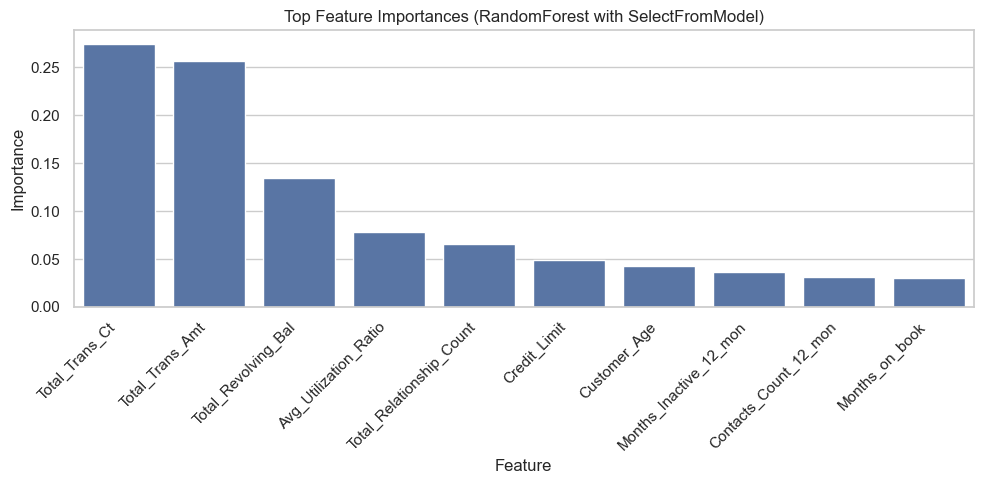

In [9]:
# Extract best model and pipeline
best_model_name = grid_search_summary.iloc[0]['estimator']
best_pipeline = grid_search_pipelines[best_model_name]

print(f"Best Performing Model: {best_model_name}\n")

# Retrieve feature names after preprocessing
encoded_cat_cols = best_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + encoded_cat_cols

# Extract selected features from SelectFromModel mask
feature_mask = best_pipeline.named_steps['feat_selection'].get_support()
selected_features = np.array(all_feature_names)[feature_mask].tolist()

print(f"Number of selected features: {len(selected_features)}")
print(f"Selected features: {selected_features}\n")

# Create feature importance DataFrame
importances = best_pipeline.named_steps['classifier'].feature_importances_
df_feature_importance = pd.DataFrame({
    'Feature': selected_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top feature importances
plt.figure(figsize=(10, 5))
sns.barplot(data=df_feature_importance.head(15), x='Feature', y='Importance')
plt.title(f"Top Feature Importances ({best_model_name} with SelectFromModel)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Conclusions and Next Steps

* **Summary**: The custom hyperparameter tuning and embedded feature selection successfully streamlined our feature space while maximizing ROC-AUC.
* **Why it is important**: For credit card churn prediction, removing noisy variables via `SelectFromModel` prevents overfitting on demographic noise, while tuned ensemble trees (Random Forest/XGBoost) reliably identify behavioural triggers (such as transaction counts and credit utilization) associated with customer attrition.
* **Next Steps**: Deploy the best pipeline into a production scoring API to flag high-risk customers for proactive retention campaigns.